# ChessLab Chess Engine Integration

Here, we will experiment with the publically available stockfish chess engine, and analyse some moves from a game.

## Workflow

1. Get PGN's from Chess.com API
2. Parse games & get game information
3. Store data in SQLite database
4. Query game data
5. Analyse moves within a game
6. Game-level analysis

In [24]:
# load necessary libraries and modules from python-chess and functions from ChessLab
import chess
import chess.engine
import pandas as pd

from pathlib import Path

from chesslab.api.chesscom import (
    get_game_archives,
    download_monthly_games,
)
from chesslab.chess.parser import (
    parse_games,
    get_game_info,
)
from chesslab.storage.database import (
    create_connection,
    create_games_table,
    save_game,
    get_games,
)

from chesslab.engine.stockfish import (
    analyse_position,
    analyse_game_moves,
)

# 1. Load Game Data for Stockfish

To test stockfish, we need to load some chess data to later analyse

In [25]:
# define username and which time period to query data from
username = "tjmoonz98"
year = 2026
month = 9

# get available game archives
archives = get_game_archives(username)
print(f"Total monthly archives: {len(archives)}")
print(archives)

# download and define the pgn object from
pgn = download_monthly_games(username, year, month)
print(f"Downloaded {len(pgn):,} characters of PGN data.")

Total monthly archives: 7
['https://api.chess.com/pub/player/tjmoonz98/games/2023/03', 'https://api.chess.com/pub/player/tjmoonz98/games/2023/04', 'https://api.chess.com/pub/player/tjmoonz98/games/2026/06', 'https://api.chess.com/pub/player/tjmoonz98/games/2026/07', 'https://api.chess.com/pub/player/tjmoonz98/games/2026/08', 'https://api.chess.com/pub/player/tjmoonz98/games/2026/09', 'https://api.chess.com/pub/player/tjmoonz98/games/2026/10']
Downloaded 187,589 characters of PGN data.


# 2. Parse Games

Parse only the games we wish to analyse later

In [26]:
# parse all games and print the length of the object
games = parse_games(pgn)
print(f"Number of games parsed: {len(games)}")

Number of games parsed: 83


In [27]:
# print first game in the list 
first_game = games[0]
print(first_game)

[Event "Live Chess"]
[Site "Chess.com"]
[Date "2026.09.30"]
[Round "-"]
[White "seyi2006"]
[Black "tjmoonz98"]
[Result "0-1"]
[CurrentPosition "8/pppk4/4p3/1N1p3N/7P/2P1P3/PP1P2r1/R1B2q1K w - - 6 33"]
[Timezone "UTC"]
[ECO "A00"]
[ECOUrl "https://www.chess.com/openings/Van-t-Kruijs-Opening-1...Nf6"]
[UTCDate "2026.09.30"]
[UTCTime "20:48:28"]
[WhiteElo "450"]
[BlackElo "461"]
[TimeControl "900+10"]
[Termination "tjmoonz98 won by checkmate"]
[StartTime "20:48:28"]
[EndDate "2026.09.30"]
[EndTime "21:04:13"]
[Link "https://www.chess.com/game/live/184623817122"]

1. e3 { [%clk 0:15:06.4] } 1... Nf6 { [%clk 0:15:05.8] } 2. Na3 { [%clk 0:15:09.7] } 2... Nc6 { [%clk 0:15:05.8] } 3. Nc4 { [%clk 0:15:18] } 3... d6 { [%clk 0:15:07.6] } 4. Qf3 { [%clk 0:15:22.1] } 4... g6 { [%clk 0:14:52.2] } 5. g4 { [%clk 0:15:30.9] } 5... Bxg4 { [%clk 0:14:56.6] } 6. Qg3 { [%clk 0:15:35] } 6... h5 { [%clk 0:14:57.1] } 7. f3 { [%clk 0:15:26.8] } 7... Nb4 { [%clk 0:14:42.6] } 8. Na3 { [%clk 0:15:30] } 8... Bf5 {

In [28]:
# test out our get_game_info function
game_info = get_game_info(first_game, username)
game_info

{'username': 'tjmoonz98',
 'white': 'seyi2006',
 'black': 'tjmoonz98',
 'result': '0-1',
 'date': '2026.09.30',
 'eco': 'A00',
 'white_elo': '450',
 'black_elo': '461',
 'time_control': '900+10',
 'termination': 'tjmoonz98 won by checkmate',
 'link': 'https://www.chess.com/game/live/184623817122'}

In [29]:
# create a df object of all parsed games in September 2026
games_df = pd.DataFrame(
    [get_game_info(game, username) for game in games]
)

games_df.head()

,username,white,black,result,date,eco,white_elo,black_elo,time_control,termination,link
0,tjmoonz98,seyi2006,tjmoonz98,0-1,2026.09.30,A00,450,461,900+10,tjmoonz98 won by checkmate,https://www.chess.com/game/live/184623817122
1,tjmoonz98,tjmoonz98,Gladiador204,0-1,2026.09.30,D02,453,467,900+10,Gladiador204 won by checkmate,https://www.chess.com/game/live/184623446172
2,tjmoonz98,Herculesbig,tjmoonz98,1-0,2026.09.30,B00,480,461,900+10,Herculesbig won by resignation,https://www.chess.com/game/live/184619918272
3,tjmoonz98,tjmoonz98,z3tarin,1-0,2026.09.29,A04,805,800,1/86400,tjmoonz98 won by resignation,https://www.chess.com/game/daily/1036570062
4,tjmoonz98,tjmoonz98,banban233,1-0,2026.09.15,B20,805,138,1/259200,tjmoonz98 won by checkmate,https://www.chess.com/game/daily/1029824750


# 4. Store Games in SQLite database

Now we know our api and parse functions work fine, let's see how the database functions work

In [30]:
# ensure directories are set up correctly and create a database in data/ 
PROJECT_ROOT = Path.cwd().parent
database_path = PROJECT_ROOT / "data" / "database.db"
database_path.parent.mkdir(parents=True, exist_ok=True)

# connect to database
connection = create_connection(database_path)
create_games_table(connection)

In [31]:
# for loop through parsed games and save each game
for game in games:
    info = get_game_info(game, username)
    save_game(connection, info, str(game))

print(f"Saved {len(games)} games.")

Saved 83 games.


In [32]:
# use get_games function to fetch previously saved games

stored_games = get_games(connection)
print(f"Total games currently in database: {len(stored_games)}")

Total games currently in database: 83


# 5. Start Stockfish Engine!

In [33]:
# deifne the stockfish path and connect to the engine
STOCKFISH_PATH = "/opt/homebrew/bin/stockfish"

engine = chess.engine.SimpleEngine.popen_uci(STOCKFISH_PATH)
print("Stockfish connected successfully.")

Stockfish connected successfully.


r n b q k b n r
p p p p p p p p
. . . . . . . .
. . . . . . . .
. . . . . . . .
. . . . . . . .
P P P P P P P P
R N B Q K B N R


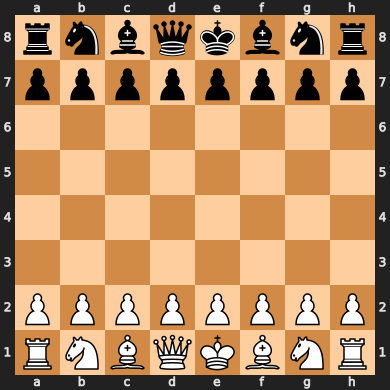

In [34]:
# define the board object
board = game.board()

# print the output and view it
print(board) 
board

# 6. Analyse Game!

Quick Note: In this game, I played Black and my oppenent opend with the e3 pawn, which was met by Knight to f6 (Nf6). The game ended in a Queen to f1 (Qf1) checkmate!

In [35]:
result = engine.analyse(
    board,
    chess.engine.Limit(depth=10),
)

print("Evaluation:", result["score"])

Evaluation: PovScore(Cp(+31), WHITE)


In [41]:

move_analysis_output = analyse_game_moves(
    first_game,
    engine,
    depth=10,
)

move_analysis_output

,move_number,player,move,eval_before_white,eval_after_white,evaluation_change_white
0,1,White,e3,0.21,0.21,0.00
1,1,Black,Nf6,0.21,0.16,-0.05
2,2,White,Na3,0.16,-0.59,-0.75
3,2,Black,Nc6,-0.63,-0.19,0.44
4,3,White,Nc4,-0.55,-1.86,-1.31
...,...,...,...,...,...,...
59,30,Black,Rg8+,-99.97,-99.98,-0.01
60,31,White,Kh2,-99.98,-99.99,-0.01
61,31,Black,Rg2+,-99.99,-99.99,0.00
62,32,White,Kh1,-99.99,-99.99,0.00


## What We've Learned

In this notebook, we have gone through the entire workflow of the project, testing each module. We have now established a connection to the Stockfish engine and analysed a recently played game!